In [88]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [89]:
df = pd.read_csv("linear_regression_data.csv")
df.head()

,CGPA,Package_LPA
0,2.5,5.5
1,2.7,6.2
2,2.8,6.8
3,2.9,7.0
4,3.0,7.5


<Axes: xlabel='CGPA', ylabel='Package_LPA'>

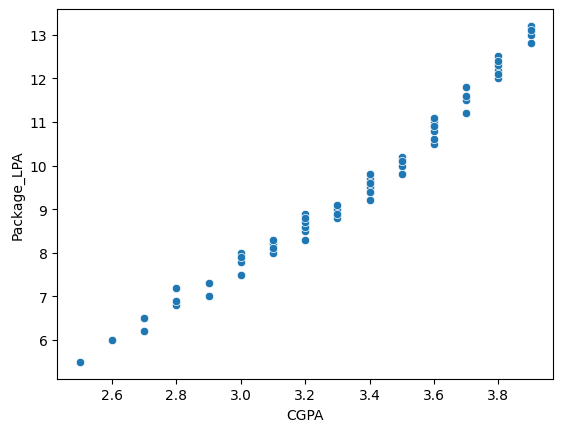

In [90]:
sns.scatterplot(x = 'CGPA' , y = 'Package_LPA' , data=df)

In [91]:
df.isnull().sum()

CGPA           0
Package_LPA    0
dtype: int64

In [92]:
x = df[['CGPA']]
y = df['Package_LPA']

In [93]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [106]:
from sklearn.svm import SVR
#kernel : {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} 
model = SVR(kernel='poly')
model.fit(x_train,y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'poly'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


In [107]:
y_pred = model.predict(x_test)
print(y_pred)

[ 5.77072482  8.03788293  8.03788293 12.76360965 12.76360965 10.73699499
  9.56036458  9.02150242 12.05190189 12.05190189  8.51432862  7.17333485]


In [108]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("MAE:", mean_absolute_error(y_test, y_pred) * 100)
print("MSE:", mean_squared_error(y_test, y_pred)* 100)
print("R2:", r2_score(y_test, y_pred)* 100)

MAE: 14.388788233331992
MSE: 3.0945818060276924
R2: 99.43313304745139


In [109]:
model.score(x_test,y_test) * 100

99.43313304745139

In [110]:
model.score(x_train,y_train) * 100

98.4359717451015

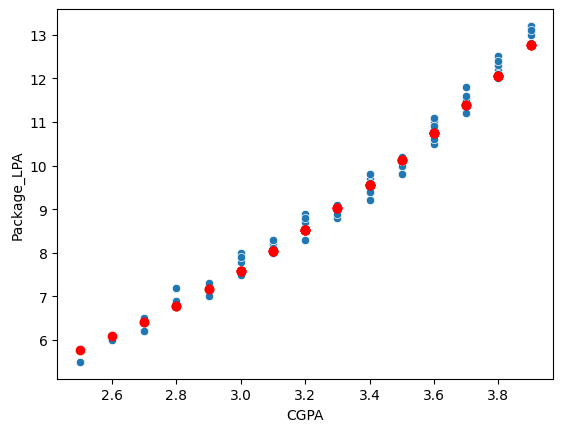

In [113]:


sns.scatterplot(x='CGPA', y='Package_LPA', data=df)

# plt.plot(df['CGPA'], model.predict(x),color= 'red')
plt.scatter(df['CGPA'], model.predict(x),color= 'red')


plt.show()

In [112]:
# compare 
pd.DataFrame({"Actual":y_test , "Predicated" : y_pred})

,Actual,Predicated
0,5.5,5.770725
5,8.0,8.037883
30,8.1,8.037883
13,12.8,12.763610
34,13.0,12.763610
55,11.1,10.736995
27,9.7,9.560365
31,8.9,9.021502
45,12.1,12.051902
12,12.0,12.051902
